# Test the custom CityscapesDataset class
This notebook is a quick test for the custom CityscapesDataset, which is used for data loading and preprocessing with transforms/augmentations for model training.

The notebook:
- Defines sample image and label transforms
- Loads data without and with transforms
- Visualizes one sample image and corresponding label
- Prints the length of the dataset and dimensions of the image/label

In [1]:
from cityscapes_dataset import CityscapesDataset
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
import torchvision.transforms.functional as F

def image_transform(image):
    image = Image.fromarray(image)
    image = F.resize(image, (256, 512), interpolation=F.InterpolationMode.BILINEAR)
    image = F.pil_to_tensor(image).float() / 255.0  # Scaling
    return image

def label_transform(label):
    label = Image.fromarray(label)  # numpy -> PIL
    label = F.resize(label, (256, 512), interpolation=F.InterpolationMode.NEAREST)
    label = F.pil_to_tensor(label).long()  # PIL -> LongTensor no Scaling
    return label

Dataset length: 2975
Shape: (1024, 2048, 3)
Shape: (1024, 2048)


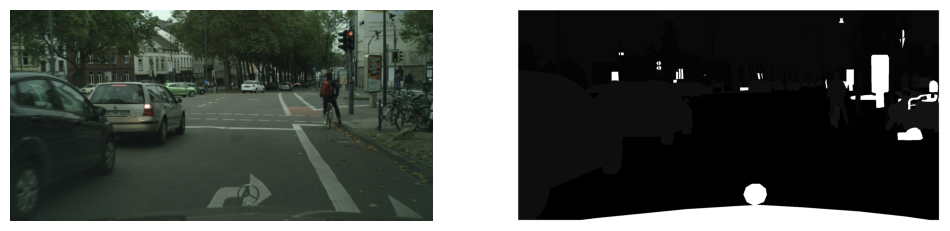

In [2]:
# Loading data without transforms
data_dir = Path("../data/Cityscapes")
img_dir = data_dir / "leftImg8bit_trainvaltest/leftImg8bit"
label_dir = data_dir / "gtFine_trainvaltest/gtFine"
csd = CityscapesDataset(img_dir, label_dir, split="train", image_transform=None, label_transform=None)
print(f"Dataset length: {csd.__len__()}")

img, label = csd.__getitem__(10)
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, img in zip(axes, [img, label]):
    print(f"Shape: {img.shape}")
    ax.imshow(img, cmap="gray")
    ax.axis("off")

Dataset length: 2975
Shape: torch.Size([256, 512, 3])
Shape: torch.Size([256, 512])


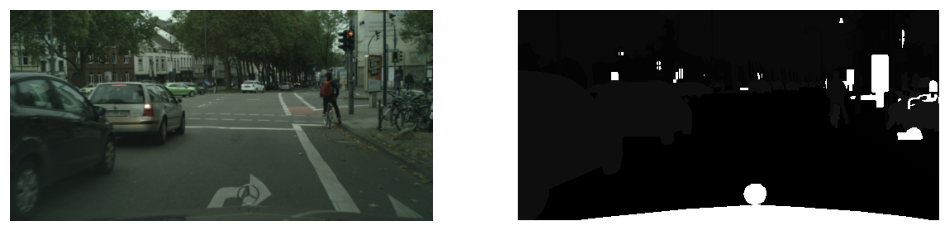

In [3]:
# Loading data with transforms
data_dir = Path("../data/Cityscapes")
img_dir = data_dir / "leftImg8bit_trainvaltest/leftImg8bit"
label_dir = data_dir / "gtFine_trainvaltest/gtFine"
csd = CityscapesDataset(img_dir, label_dir, split="train", image_transform=image_transform, label_transform=label_transform)
print(f"Dataset length: {csd.__len__()}")

img, label = csd.__getitem__(10)
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, img in zip(axes, [img.permute(1, 2, 0), label.squeeze(0)]):
    print(f"Shape: {img.shape}")
    ax.imshow(img, cmap="gray")
    ax.axis("off")